--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
display(plans.head())
#mostrar las primeras 5 filas de plans


,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
display(users.head())
# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
display(usage.head())
# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()
# inspección de plans con .info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()
# inspección de users con .info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()
# inspección de usage con .info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


  City (14.13%): Se identificaron 565 clientes sin ciudad válida. Se recomienda mantenerlos como valores nulos para evitar asignar ubicaciones incorrectas.

Churn_date (88.35%): Los valores nulos podrían representar clientes activos. Se recomienda conservar la columna y confirmar esta interpretación antes de realizar ajustes.

Date (0.13%): Existen 50 registros sin fecha. Se recomienda excluirlos únicamente de análisis temporales si no se puede recuperar la información.

Duration (55.19%) y length (44.74%): Los valores nulos se explican principalmente por la diferencia entre llamadas y mensajes. Se recomienda conservarlos y revisar las inconsistencias detectadas antes de cualquier imputación.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
display(users[['user_id', 'age']].describe())
# explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`: Presenta valores entre 10000 y 13999. Es un identificador de clientes, por lo que no debe analizarse como una variable numérica de comportamiento. Se recomienda verificar que no existan identificadores duplicados.
- La columna `age`: Se identificó un valor mínimo de -999, que representa una edad inválida o sentinel. Este valor afecta el promedio de edad, por lo que se recomienda convertirlo a nulo antes del análisis estadístico.

In [13]:
display(usage[['id', 'user_id', 'duration', 'length']].describe())
# explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`: : Presentan rangos coherentes de identificadores. Se recomienda comprobar la unicidad de id y que los identificadores de clientes correspondan a registros existentes en users.
- Las columnas duration y length: Se encontraron valores mínimos de 0 y máximos de 120 y 1490, respectivamente. Se recomienda investigar los ceros y los valores extremos, así como los registros que contienen datos en ambas columnas, antes de decidir si requieren corrección.

In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print("Columna:", col)
    print("Valores únicos:")
    print(users[col].unique())
    print("Frecuencia:")
    display(users[col].value_counts(dropna=False))

Columna: city
Valores únicos:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
Frecuencia:


Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Columna: plan
Valores únicos:
['Basico' 'Premium']
Frecuencia:


Basico     2595
Premium    1405
Name: plan, dtype: int64

- La columna `city` Se identificaron valores faltantes y el símbolo ? como valor inválido. Se recomienda convertir ? a nulo y conservar los registros para no perder información de clientes.
- La columna `plan` Se encontraron únicamente las categorías Básico y Premium, ambas válidas. No requiere corrección.

In [15]:
# explorar columna categórica de usage
usage['type'] # completa el código

print("Valores únicos:")
print(usage['type'].unique())

print("Frecuencia:")
display(usage['type'].value_counts(dropna=False))

Valores únicos:
['call' 'text']
Frecuencia:


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` Se encontraron únicamente call y text, con 17,908 y 22,092 registros, respectivamente. No requiere corrección.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  En la columna city se identificaron 96 registros con el símbolo ?, que representa información desconocida. Adicionalmente, en usage se detectaron 12 llamadas con valores registrados en length, una columna normalmente asociada con mensajes, por lo que requieren revisión.
Las columnas plan y type contienen únicamente categorías válidas.
- ¿Qué acción tomarías?

Se recomienda convertir los símbolos ? de city a valores nulos, conservando los registros de los clientes. Para usage, se deben investigar las inconsistencias antes de modificarlas o eliminar registros. Las columnas categóricas válidas no requieren correcciones.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:


# Convertir a fecha
users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)

# Mostrar cuántas veces aparece cada año
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())
# Revisar los años presentes en `reg_date` de users



2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`: Se identificaron 40 registros correspondientes a 2026, fuera del periodo de análisis establecido hasta 2024. Se recomienda investigar estas fechas y corregirlas únicamente si es posible verificar los valores originales. De lo contrario, deben tratarse como fechas inválidas para el análisis.

In [17]:

# Convertir a fecha
usage['date'] = pd.to_datetime(
    usage['date'],
    errors='coerce'
)

# Mostrar cuántas veces aparece cada año
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

# Revisar los años presentes en `date` de usage


2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`: Se encontraron 39,950 registros correspondientes a 2024 y 50 registros sin fecha válida. Se recomienda conservar los registros, pero excluir los que no tienen fecha de los análisis temporales si no es posible recuperar esta información.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

Se detectaron 40 fechas de registro de clientes correspondientes al año 2026, aunque el proyecto contempla información únicamente hasta 2024. Estas fechas se consideran inconsistentes y deben investigarse antes de realizar análisis de antigüedad o comportamiento de los clientes.

En el dataset usage, los 39,950 registros con fecha válida pertenecen a 2024. Los 50 registros restantes presentan fechas faltantes.

Recomendación: No modificar automáticamente las fechas de 2026 para convertirlas en 2024, ya que esto implicaría inventar información. Se recomienda revisar su origen y, si no es posible corregirlas con evidencia, marcarlas como inválidas. Los registros sin fecha deben excluirse únicamente de los cálculos que dependan del tiempo.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [18]:
age_mediana = users.loc[users['age'] != -999, 'age'].median()

users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

# Reemplazar -999 por la mediana de age



count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [19]:
users['city'] = users['city'].replace('?', pd.NA)
# Reemplazar ? por NA en city

print(users['city'].isna().sum())
# Verificar cambios


565


In [20]:

users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)

users.loc[
    users['reg_date'].dt.year > 2024,
    'reg_date'
] = pd.NaT
# Marcar fechas futuras como NA para reg_date

print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())
# Verificar cambios


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [21]:
display(
    usage.groupby('type')['duration']
    .apply(lambda x: x.isna().mean() * 100)
)
# Verificación MAR en usage (Missing At Random) para duration


type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [22]:
display(
    usage.groupby('type')['length']
    .apply(lambda x: x.isna().mean() * 100)
)
# Verificación MAR en usage (Missing At Random) para length


type
call    99.932991
text     0.000000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length':
Se observa que los valores faltantes dependen directamente del tipo de servicio (type). La columna duration está prácticamente completa para llamadas (call), pero presenta valores nulos en casi todos los mensajes (text). Por el contrario, length está completa para mensajes y casi totalmente vacía para llamadas.

Este comportamiento es consistente con un patrón de ausencia explicado por una variable observada, compatible con MAR según el enfoque del ejercicio, aunque más específicamente corresponde a valores faltantes estructurales.

Recomendación: Conservar los valores nulos sin imputarlos, ya que cada variable corresponde a un tipo de servicio distinto. Reemplazarlos por ceros distorsionaría los análisis de duración de llamadas y longitud de mensajes. Se recomienda revisar por separado los registros excepcionales que contienen información en ambas columnas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [23]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Considerar minutos solamente en llamadas
usage["minutos_llamada"] = usage["duration"].where(
    usage["type"] == "call", 0
)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "minutos_llamada": "sum"
}).reset_index()

# Observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [24]:
# Renombrar columnas

usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "minutos_llamada": "cant_minutos_llamada"
})

# Observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [25]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)

# Observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [26]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

display(user_profile[columnas_numericas].describe())

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,22.836934
std,17.689919,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [27]:
# Distribución porcentual del tipo de plan
display(
    user_profile['plan'].value_counts(normalize=True) * 100
)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

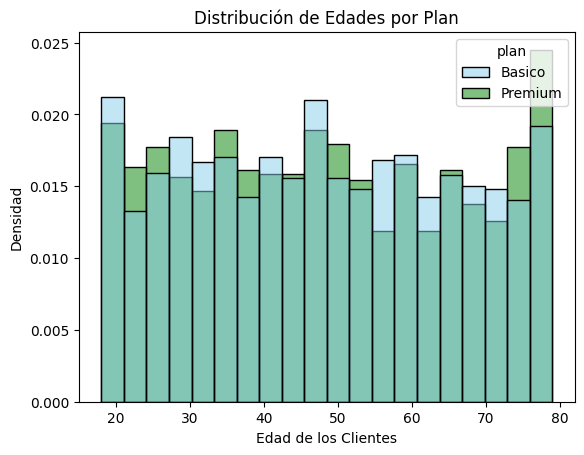

In [28]:
# Histograma para visualizar la edad (age)

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    stat='density',
    common_norm=False
)

plt.title('Distribución de Edades por Plan')
plt.xlabel('Edad de los Clientes')
plt.ylabel('Densidad')
plt.show()

💡Insights: 
- Distribución ...

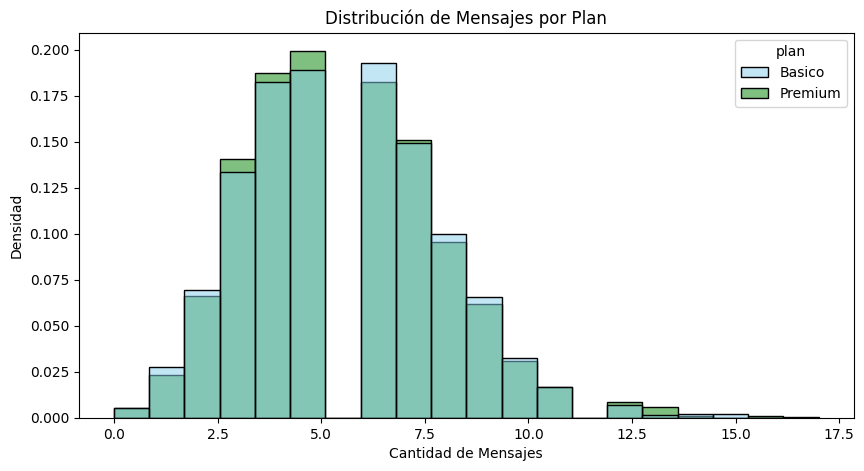

In [34]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    stat='density',
    common_norm=False
)

plt.title('Distribución de Mensajes por Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Densidad')
plt.show()


💡Insights: 
- ....

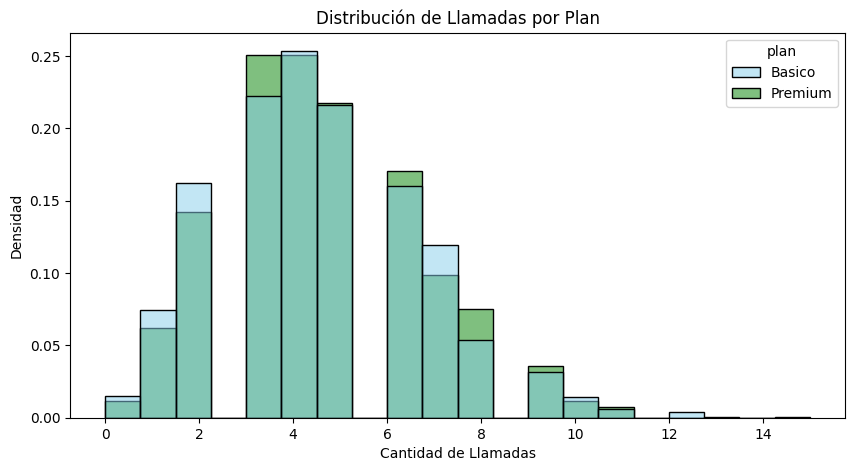

In [36]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    stat='density',
    common_norm=False
)

plt.title('Distribución de Llamadas por Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Densidad')
plt.show()


💡Insights: 
- Distribución ...

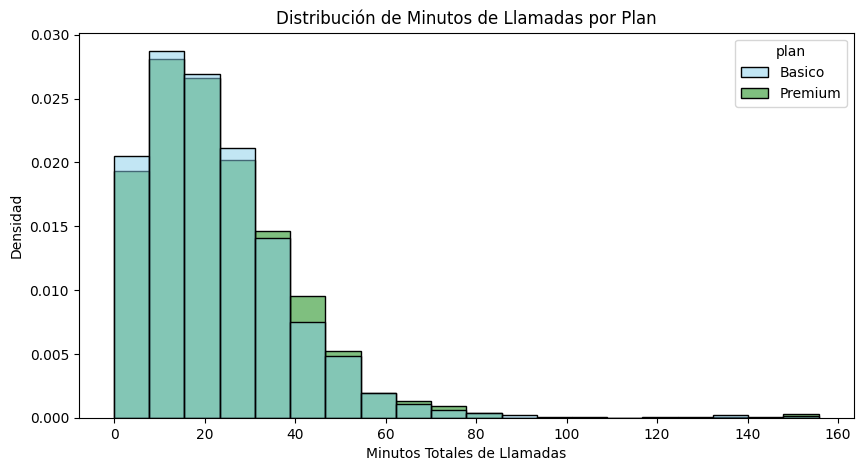

In [37]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    stat='density',
    common_norm=False
)

plt.title('Distribución de Minutos de Llamadas por Plan')
plt.xlabel('Minutos Totales de Llamadas')
plt.ylabel('Densidad')
plt.show()

💡Insights: 
- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

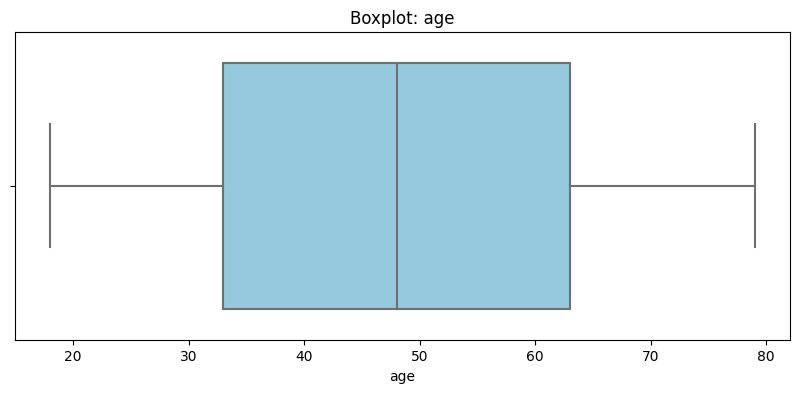

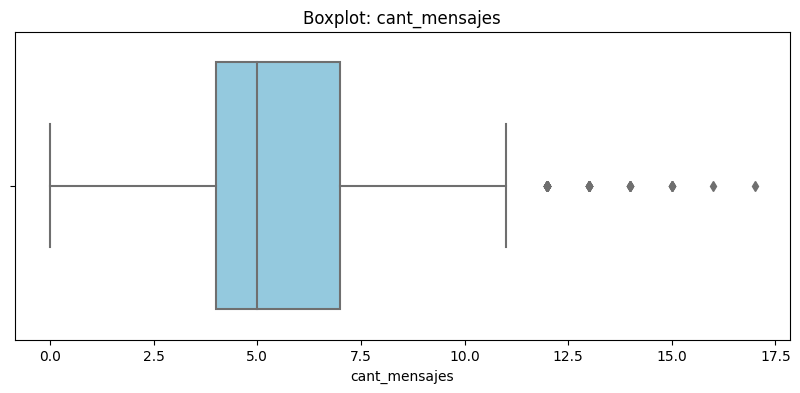

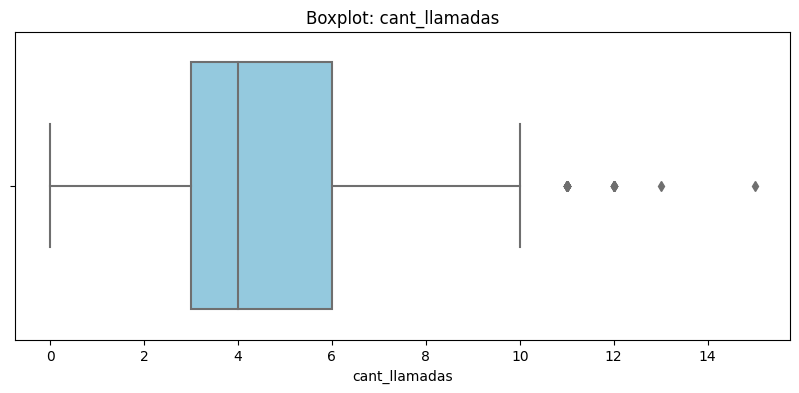

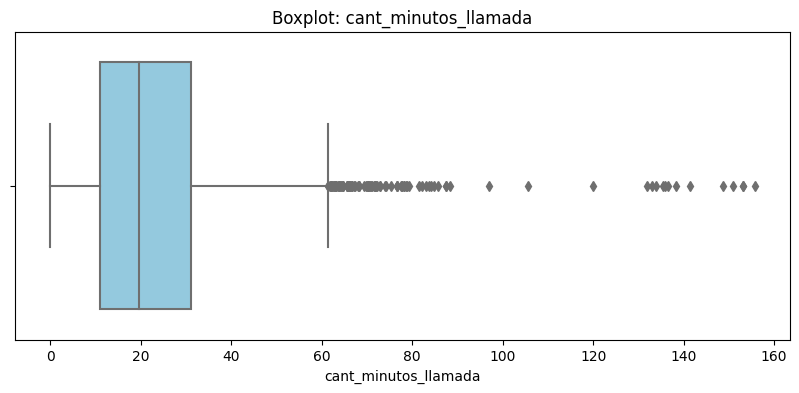

In [38]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
col_minutos = (
    'total_minutos_llamada'
    if 'total_minutos_llamada' in user_profile.columns
    else 'cant_minutos_llamada'
)

columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    col_minutos
]

# Crear los 4 boxplots
for col in columnas_numericas:
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=user_profile[col],
        color='skyblue'
    )

    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()
    

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [39]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    limite_inferior = Q1 - 1.5 * IQR

    outliers = user_profile[
        (user_profile[col] < limite_inferior) |
        (user_profile[col] > limite_superior)
    ]

    print(f'Columna: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Valor máximo: {user_profile[col].max():.2f}')
    print(f'Cantidad de outliers: {len(outliers)}')
    print()



Columna: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50
Valor máximo: 17.00
Cantidad de outliers: 46

Columna: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50
Valor máximo: 15.00
Cantidad de outliers: 30

Columna: cant_minutos_llamada
Límite inferior: -19.04
Límite superior: 61.32
Valor máximo: 155.69
Cantidad de outliers: 96



In [40]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [44]:

import numpy as np

# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),

    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10)
]

segmentos = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    segmentos,
    default='Alto uso'
)


In [42]:
# verificar cambios
display(user_profile.head())

# Contar usuarios por segmento
display(user_profile['grupo_uso'].value_counts())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [45]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

segmentos_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad,
    segmentos_edad,
    default='Adulto Mayor'
)

In [46]:
# verificar cambios
display(user_profile.head())

# Contar clientes por grupo de edad
display(user_profile['grupo_edad'].value_counts())

# Verificar edades faltantes
print(user_profile['age'].isna().sum())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

0


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [ ]:
# Visualización de los segmentos por uso

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de Clientes por Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Clientes')
plt.show()

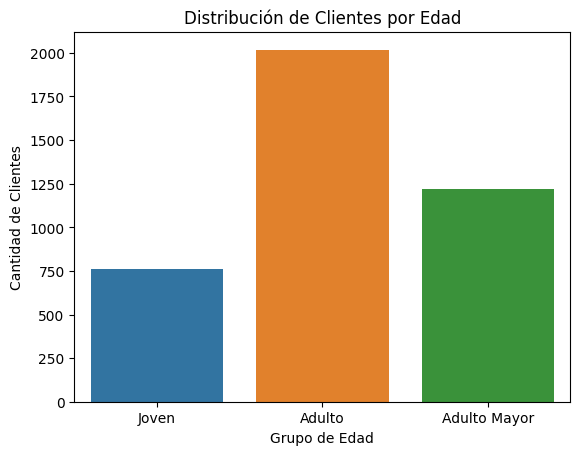

In [47]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.title('Distribución de Clientes por Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Clientes')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Durante la exploración de los 4,000 clientes y 40,000 registros de uso se identificaron problemas de calidad que podrían afectar los resultados:

Edades inválidas: 55 clientes (1.38%) presentaban el valor -999. Se sustituyó por la mediana de las edades válidas para evitar distorsiones en el análisis.

Ciudades faltantes: Se identificaron 469 valores nulos y 96 registros con ?, equivalentes a 565 clientes (14.13%). Los valores inválidos se estandarizaron como nulos.

Fechas fuera de rango: Se detectaron 40 registros de clientes correspondientes a 2026 (1%), aunque el periodo del proyecto termina en 2024. Se marcaron como fechas inválidas.

Fechas faltantes de consumo: 50 de los 40,000 registros (0.13%) no tenían una fecha válida. Estos registros requieren un tratamiento específico para los análisis temporales.

Valores ausentes en llamadas y mensajes: Los nulos de duration y length están asociados principalmente al tipo de servicio. Se conservaron porque estas variables no aplican de la misma forma a llamadas y mensajes.


🔍 **Segmentos por Edad**

Se clasificaron los clientes en tres grupos: Jóvenes (menores de 30 años), Adultos (30 a 59 años) y Adultos Mayores (60 años o más).

La distribución general de edades es relativamente uniforme, entre aproximadamente 18 y 79 años.

Los clientes de los planes Básico y Premium muestran distribuciones de edad similares, sin diferencias visuales marcadas.

Implicación: La edad por sí sola no parece suficiente para explicar la elección de un plan. Conviene combinarla con el comportamiento real de consumo para diseñar estrategias comerciales más específicas.

📊 **Segmentos por Nivel de Uso**

Los clientes fueron clasificados de acuerdo con la cantidad de llamadas y mensajes registrados:

Bajo uso: Menos de 5 llamadas y menos de 5 mensajes.

Uso medio: Menos de 10 llamadas y menos de 10 mensajes, sin cumplir las condiciones de Bajo uso.

Alto uso: Clientes que superan al menos uno de los límites del grupo Uso medio.

Esta segmentación permite diferenciar a los clientes según su comportamiento, identificar oportunidades de mejora en los planes y desarrollar estrategias de retención.


💡 **Recomendaciones**

Mejorar la calidad de los datos: Implementar validaciones automáticas para edades, fechas y ciudades, evitando registros inválidos desde su origen.

Personalizar la oferta: Evaluar planes o paquetes adicionales para clientes de alto consumo y alternativas más económicas para clientes con baja utilización.

Fortalecer la retención: Cruzar el nivel de consumo, la edad, el plan contratado y los registros de abandono para identificar grupos con mayor riesgo de cancelación.

Evaluar la rentabilidad: Comparar ingresos potenciales por plan con el consumo real antes de recomendar migraciones hacia Premium.

Monitorear patrones de consumo: Crear indicadores periódicos de llamadas, mensajes, minutos utilizados y clientes con consumos atípicos.

Conclusion

El análisis de ConectaTel evidencia la importancia de limpiar y validar los datos antes de utilizarlos para tomar decisiones.

La segmentación por edad y nivel de uso proporciona una base para comprender mejor a los clientes. El siguiente paso comercial debe ser relacionar esos comportamientos con ingresos, costos y abandono para identificar oportunidades concretas de crecimiento y retención.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`